In [1]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import sys
sys.path.insert(0, "CMake")

import sets_of_point
import cross_intersection
import fitting_rad

In [2]:
a=1.098
b=1.2
def update(l, new):
    l.append(int(new))
    return l[1:]

def check(back, forward):
    #print(forward, back)
    relate = np.abs(max(np.mean(back), np.mean(forward))/min(np.mean(back), np.mean(forward)))
    if (relate >= a
    and min(np.mean(back), np.mean(forward)) >100 and
    relate <= b
    and max(np.mean(back), np.mean(forward)<150) and np.abs(relate-1)>0.1):
        if (min(float(back[-1]), float(forward[-1])) ==0):
            return True
        elif (min(float(back[-1]), float(forward[-1])) != 0 
            and max(float(forward[-1]), float(back[-1]))/min(float(back[-1]), float(forward[-1])) < b
            and max(float(forward[-1]), float(back[-1]))/min(float(back[-1]), float(forward[-1])) > a):
            return True
        else:
            False


def check_back(back, forward):
    if np.abs(np.mean(back)/np.mean(forward))  >= 1.5:
        return False
    else: 
        return True

/var/folders/bq/1j_8mtdd1ssfmh927lzsd3br0000gn/T/ipykernel_36468/2139658912.py:9: RuntimeWarning: divide by zero encountered in scalar divide
  relate = np.abs(max(np.mean(back), np.mean(forward))/min(np.mean(back), np.mean(forward)))
/var/folders/bq/1j_8mtdd1ssfmh927lzsd3br0000gn/T/ipykernel_36468/2139658912.py:9: RuntimeWarning: invalid value encountered in scalar divide
  relate = np.abs(max(np.mean(back), np.mean(forward))/min(np.mean(back), np.mean(forward)))
/var/folders/bq/1j_8mtdd1ssfmh927lzsd3br0000gn/T/ipykernel_36468/1832354485.py:77: RuntimeWarning: divide by zero encountered in scalar divide
  k += [-(grady-1)/(gradx-1)]
/var/folders/bq/1j_8mtdd1ssfmh927lzsd3br0000gn/T/ipykernel_36468/1832354485.py:77: RuntimeWarning: invalid value encountered in scalar divide
  k += [-(grady-1)/(gradx-1)]
/Users/alex_wan/Documents/TEM statistics/MoS2 ablation in N2/F5-D8 MoS2_N2_abl_scan_1kHz_100uJ/.venv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of

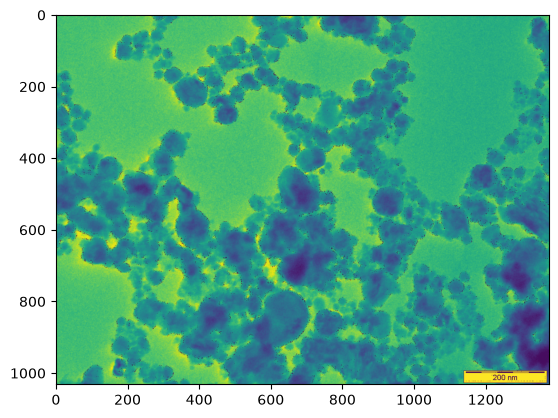

In [3]:
r = []
R = []
for q in range(3, 9):
    a=1.175
    b=1.335
    im = Image.open(f'MoS2_{q}.tif')
    M = np.array(im)
    #M = M[600:800, 400:750]
    places1 = []
    grad = []

    back = [160]*4
    back2 = back.copy() ##
    background = []
    forward = []
    for i in range(len(M)):
        #forward = list(M[i][0:4])
        #back = forward
        for j in range(8, len(M[0])-4):
            forward = list(M[i][j-4:j])
            back = list(M[i][j-8:j-4])
            if (not(check(back, forward)) and max(np.mean(back), np.mean(forward))==np.mean(back) and
                check(forward, list(M[i][j:j+4]))) or (
                    (check(back, forward)) and max(np.mean(back), np.mean(forward))==np.mean(forward) and
                not(check(forward, list(M[i][j:j+4])))
                ):#and not(check(back2, back) or check(back2, forward)):
                    places1+= [[i, j-2]]

    places2 = []
    grad = []

    back = [160]*4
    back2 = back.copy() ##
    background = []
    forward = []
    for j in range(len(M[0])):
        #forward = [M[l][j] for l in range(4)]
        #back = forward
        for i in range(8, len(M)-4):
            forward = [M[l][j] for l in range(i-4, i)]
            back = [M[l][j] for l in range(i-8, i-4)]
            if (not(check(back, forward)) and max(np.mean(back), np.mean(forward))==np.mean(back) and 
                check(forward, list(M[l][j] for l in range(i, i+4)))) or (
                     (check(back, forward)) and max(np.mean(back), np.mean(forward))==np.mean(forward) and 
                not(check(forward, list(M[l][j] for l in range(i, i+4))))
                ): #and not(check(back2, back) or check(back2, forward)):
                    places2+= [[i-2, j]]

    set1 = {tuple(p) for p in places1}
    places_12 = [p for p in places2 if tuple(p) in set1]
    places_12 = [places_12[0]]
    places_sum = places1+places2
    indices = np.random.choice(len(places1), int(len(places1)/3))
    places_12 = np.vstack([places_12, np.array(places1)[indices]])
    indices = np.random.choice(len(places2), int(len(places2)/3))
    places_12 = np.vstack([places_12, np.array(places2)[indices]])
    places = places_12
    places = places[places[:, 0] < len(M)-5]
    M_=M.copy()
    for i in range(len(places)):
            M_[places[i][0]][places[i][1]] = 0

    #M_ = M_[300:600, 500:800]

    plt.imshow(M_)
    plt.savefig(f"new{q}.pdf")   
    grad = []
    k = []
    b = []
    
    """можно поставить фильтр на градиенты"""
    for i in range(len(places)):
        gradx = np.mean(M[places[i][0]][places[i][1]:places[i][1]+4])/np.mean(M[places[i][0]][places[i][1]-4:places[i][1]])
        grady = np.mean([M[l][places[i][1]] for l in range(places[i][0], places[i][0]+4)])/np.mean([M[l][places[i][1]] for l in range(places[i][0]-4, places[i][0])])
        places[i][0] = len(M_)-places[i][0]

        k += [-(grady-1)/(gradx-1)]
        b += [places[i][0]-k[-1]*places[i][1]]
        #print(gradx)
        grad += [[ -(grady-1), (gradx-1)]]
    result = cross_intersection.cross_intersect(k, b, places, grad)
    result2 = sets_of_point.statistick(result[0], result[1])
    result3 = sets_of_point.sort_dat(result2[0], result2[1])
    result4 = fitting_rad.fitting_radius(result3[0], result3[1], places)
    result4_2 = np.array(result4)[2][np.array(result4)[2]>0.1]
    r += [np.array(result3[0])[:, 2][np.array(result3[0])[:,3]>1.0]]
    R += [result4_2]
    


(array([41., 72., 88., 65., 76., 60., 48., 53., 39., 27., 48., 64., 66.,
        90., 60., 36., 20., 10.,  3.,  3.,  1.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  1.]),
 array([  6.02969837,  13.98324944,  21.93680051,  29.89035158,
         37.84390265,  45.79745372,  53.75100479,  61.70455586,
         69.65810693,  77.611658  ,  85.56520907,  93.51876014,
        101.47231121, 109.42586228, 117.37941335, 125.33296442,
        133.28651549, 141.24006656, 149.19361763, 157.1471687 ,
        165.10071977, 173.05427084, 181.00782191, 188.96137298,
        196.91492405, 204.86847512, 212.82202619, 220.77557726,
        228.72912833, 236.6826794 , 244.63623047]),
 <BarContainer object of 30 artists>)

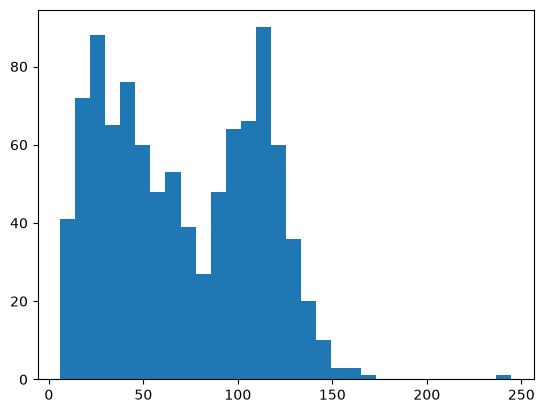

In [4]:
r_stat = []
for i in range(len(R)):
    for j in range(len(R[i])):
        r_stat += [R[i][j]]

hist = plt.hist((r_stat), 30)
y = hist[0]
x = hist[1][:-1]+(hist[1][1]-hist[1][0])/2
hist

In [5]:

"""y = np.array([23., 59., 65., 49., 45., 50., 50., 49., 41., 47., 44., 35., 32.,
        36., 31., 30., 40., 53., 73., 50., 46., 47., 23., 15., 15.,  1.,
         4.,  2.,  0.,  3.])
x = np.array([  6.52084541,  12.11856162,  17.71627782,  23.31399403,
         28.91171023,  34.50942643,  40.10714264,  45.70485884,
         51.30257505,  56.90029125,  62.49800746,  68.09572366,
         73.69343987,  79.29115607,  84.88887227,  90.48658848,
         96.08430468, 101.68202089, 107.27973709, 112.8774533 ,
        118.4751695 , 124.0728857 , 129.67060191, 135.26831811,
        140.86603432, 146.46375052, 152.06146673, 157.65918293,
        163.25689913, 168.85461534, 174.45233154])
x = x[:-1]+(x[1]-x[0])/2"""

'y = np.array([23., 59., 65., 49., 45., 50., 50., 49., 41., 47., 44., 35., 32.,\n        36., 31., 30., 40., 53., 73., 50., 46., 47., 23., 15., 15.,  1.,\n         4.,  2.,  0.,  3.])\nx = np.array([  6.52084541,  12.11856162,  17.71627782,  23.31399403,\n         28.91171023,  34.50942643,  40.10714264,  45.70485884,\n         51.30257505,  56.90029125,  62.49800746,  68.09572366,\n         73.69343987,  79.29115607,  84.88887227,  90.48658848,\n         96.08430468, 101.68202089, 107.27973709, 112.8774533 ,\n        118.4751695 , 124.0728857 , 129.67060191, 135.26831811,\n        140.86603432, 146.46375052, 152.06146673, 157.65918293,\n        163.25689913, 168.85461534, 174.45233154])\nx = x[:-1]+(x[1]-x[0])/2'

In [6]:
from scipy.optimize import curve_fit

In [7]:
def normal_pdf(s1, s2, mu1, mu2, A1, A2, x):
    f1 = A1/s1/np.sqrt(2*np.pi)*np.exp(-(x-mu1)**2 /2/(s1**2))
    f2 = A2/s2/np.sqrt(2*np.pi)*np.exp(-(x-mu2)**2 /2/(s2**2))
    return f1, f2, f1 + f2

In [8]:
def func(x, s1, s2, mu1, mu2, A1, A2):
    f1 = A1/s1/np.sqrt(2*np.pi)*np.exp(-(x-mu1)**2 /2/(s1**2))
    f2 = A2/s2/np.sqrt(2*np.pi)*np.exp(-(x-mu2)**2 /2/(s2**2))
    return f1 + f2

In [9]:
result = curve_fit(func, x, ydata=y,p0=[8.0, 8.0, 20, 80, 100, 100])
print(np.diag(np.sqrt(result[1])))
result = result[0]

[  3.11399503   1.29009195   2.04719101   1.30109196 466.5796604
 248.56322164]


/var/folders/bq/1j_8mtdd1ssfmh927lzsd3br0000gn/T/ipykernel_36468/3636691348.py:2: RuntimeWarning: invalid value encountered in sqrt
  print(np.diag(np.sqrt(result[1])))


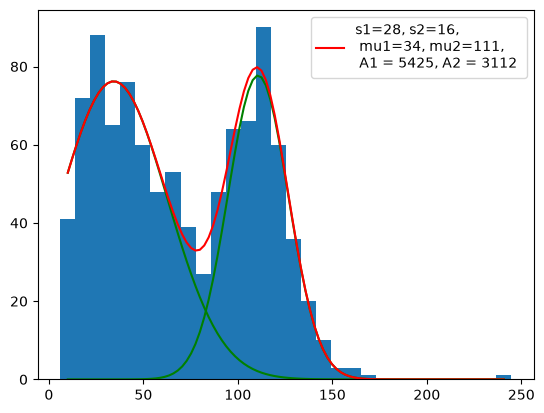

In [11]:
x_ = np.linspace(min(x), max(x), 100)
res = normal_pdf(*result, x_)
y1 = res[0]
y2 = res[1]
y3 = res[2]
plt.plot(x_, y1, c="g")
plt.plot(x_, y2, c="g")
plt.plot(x_, y3, c="r", label=f"s1={result[0]:.0f}, s2={result[1]:.0f}, \n mu1={result[2]:.0f}, mu2={result[3]:.0f}, \n A1 = {result[4]:.0f}, A2 = {result[5]:.0f} ")
plt.bar(x, y, width=x[1]-x[0])
plt.legend()